# Whiff Prediction

## Imports and Data Preparation

In [1]:
import pandas as pd
from pathlib import Path

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [10]:
ROOT = Path.cwd().parent.parent
DATA_DIR = ROOT / "data"
csv_path = DATA_DIR / "raw" / "mlb_pitches_2026_raw.csv"
pitches = pd.read_csv(csv_path)
pitches.shape

(716792, 119)

## Feature Selection

### Creating `is_whiff` Column

In [11]:
contact_events = {
    "foul",
    "foul_tip",
    "foul_bunt",
    "bunt_foul_tip",
    "hit_into_play",
}
whiff_events = {
    "swinging_strike",
    "swinging_strike_blocked",
    "missed_bunt",
    "swinging_pitchout",
}
pitches["is_swing"] = pitches["description"].isin(contact_events | whiff_events)
pitches["is_whiff"] = pitches["description"].isin(whiff_events)
pitches[["description", "is_swing", "is_whiff"]].head(5)

,description,is_swing,is_whiff
0,swinging_strike,True,True
1,swinging_strike,True,True
2,called_strike,False,False
3,hit_into_play,True,False
4,hit_into_play,True,False


### Selecting Relevant Features

Use pitch characteristics, pitch type, count, inning context, batter, and pitcher as predictors. Exclude `description` and `is_swing` because they are derived from the event used to create `is_whiff`; retaining them would leak the answer into the features. Keep `is_whiff` as the target.

In [12]:
pitches = pitches.drop(columns=["description", "is_swing"], errors="ignore")
feature_columns = [
    "pitch_type",
    "release_speed",
    "release_pos_x",
    "release_pos_z",
    "zone",
    "stand",
    "p_throws",
    "balls",
    "strikes",
    "outs_when_up",
    "inning",
    "inning_topbot",
    "pitcher",
    "batter",
]
category_columns = ["pitch_type", "stand", "p_throws", "inning_topbot", "pitcher", "batter"]
numeric_columns = [column for column in feature_columns if column not in category_columns]

X = pitches[feature_columns]
y = pitches["is_whiff"].astype(int)

## Model Pipeline

### Train-Test Split and Column Transformations

Use a stratified 70/30 split so the whiff proportion is similar in training and testing data. Impute missing numeric values with the training-set median and missing categorical values with the training-set mode rather than dropping rows; this retains pitches with partially missing predictors. Standardize numeric features and one-hot encode categorical features. Fit both models within pipelines so transformations are learned only from training data.

In [31]:
# Split into Train (60%), Validation (20%), and Test (20%)
X_train, X_tmp, y_train, y_tmp = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.5, random_state=42, stratify=y_tmp
)
print(f"Train rows: {len(X_train):,}; validation rows: {len(X_val):,}; test rows: {len(X_test):,}")

Train rows: 430,075; validation rows: 143,358; test rows: 143,359


### Column Transformation

1. We impute all columns using the median (most frequent for non-numerical)
    1.1. Why?
2. Scaling
3. Categorizing / One-Hot Encoding

For numerical columns, we want them to all follow the same scale -- TODO: why?
For categorical columns, we split them with one hot encoding

In [32]:
# Column Transformer
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline(
                steps=[
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                ]
            ),
            numeric_columns,
        ),
        (
            "categorical",
            Pipeline(
                steps=[
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("one_hot", OneHotEncoder(handle_unknown="ignore")),
                ]
            ),
            category_columns,
        ),
    ]
)
preprocessor

ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['release_speed', 'release_pos_x',
                                  'release_pos_z', 'zone', 'balls', 'strikes',
                                  'outs_when_up', 'inning']),
                                ('categorical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('one_hot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['pitch_type', 'stand', 'p_throws',
                                  'inning_topbot', 'pitcher', 'batter'])])

## Logistic Regression

In [33]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("classification", LogisticRegression(
            random_state=42,
            class_weight="balanced",
            max_iter=500
        )),
    ]
)
logistic_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['release_speed',
                                                   'release_pos_x',
                                                   'release_pos_z', 'zone',
                                                   'balls', 'strikes',
                                                   'outs_when_up', 'inning']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('one_hot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['pitch_type', 'stand',
                                                   'p_throws', 'inning_topbot',
                                                   'pitcher', 'batter'])])),
                ('classification',
                 LogisticRegression(class_weight='balanced', max_iter=500,
                                    random_state=42))])

#### Selecting Optimal Threshold

TODO: Plot the ROC-AUC curve for threshold selection
TODO: Select and compare the optimal parameters, including threshold

In [36]:
from sklearn.metrics import precision_recall_curve
import numpy as np

y_val_probs = logistic_model.predict_proba(X_val)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_val, y_val_probs)

f1_scores = 2 * (precisions * recalls) / (precisions + recalls)
f1_scores[np.isnan(f1_scores)] = 0
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 1.0

y_test_probs = logistic_model.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_probs >= best_threshold).astype(int)
print(classification_report(y_test, y_test_pred, target_names=["No Whiff", "Whiff"]))

/var/folders/pw/837z_3hs37909c7r_ll8bpm00000gn/T/ipykernel_3452/604683679.py:7: RuntimeWarning: invalid value encountered in divide
  f1_scores = 2 * (precisions * recalls) / (precisions + recalls)


              precision    recall  f1-score   support

    No Whiff       0.92      0.68      0.78    127778
       Whiff       0.17      0.54      0.26     15581

    accuracy                           0.66    143359
   macro avg       0.55      0.61      0.52    143359
weighted avg       0.84      0.66      0.72    143359



In [20]:
best_f1 = 0
best_threshold = 0.5
for i in range(1, 6):
    threshold = i * 0.1
    predictions = (logistic_scores >= threshold).astype(int)
    f1 = f1_score(y_test, predictions)
    if f1 > best_f1:
        best_f1 = f1
        best_threshold = threshold
    print(f"Threshold: {threshold:.1f}")
    print(f"Accuracy: {accuracy_score(y_test, predictions):.4f}")
    print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, predictions):.4f}")
    print(f"Precision: {precision_score(y_test, predictions):.4f}")
    print(f"Recall: {recall_score(y_test, predictions):.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"Average Precision: {average_precision_score(y_test, logistic_scores):.4f}")
    print(f"ROC AUC Score: {roc_auc_score(y_test, logistic_scores):.4f}")
    # print(confusion_matrix(y_test, predictions))
    # print(classification_report(y_test, predictions))
    print()

best_threshold, best_f1

Threshold: 0.1
Accuracy: 0.1117
Balanced Accuracy: 0.5015
Precision: 0.1090
Recall: 0.9995
F1 Score: 0.1965
Average Precision: 0.1761
ROC AUC Score: 0.6563

Threshold: 0.2
Accuracy: 0.1450
Balanced Accuracy: 0.5167
Precision: 0.1120
Recall: 0.9916
F1 Score: 0.2013
Average Precision: 0.1761
ROC AUC Score: 0.6563

Threshold: 0.3
Accuracy: 0.2472
Balanced Accuracy: 0.5551
Precision: 0.1212
Recall: 0.9486
F1 Score: 0.2150
Average Precision: 0.1761
ROC AUC Score: 0.6563

Threshold: 0.4
Accuracy: 0.4115
Balanced Accuracy: 0.5983
Precision: 0.1375
Recall: 0.8371
F1 Score: 0.2362
Average Precision: 0.1761
ROC AUC Score: 0.6563

Threshold: 0.5
Accuracy: 0.5989
Balanced Accuracy: 0.6141
Precision: 0.1601
Recall: 0.6335
F1 Score: 0.2556
Average Precision: 0.1761
ROC AUC Score: 0.6563



(0.5, 0.2555909440085623)

## Linear Regression

In [13]:
linear_model = Pipeline(
    steps=[("preprocessor", clone(preprocessor)), ("regression", LinearRegression())]
)
linear_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['release_speed',
                                                   'release_pos_x',
                                                   'release_pos_z', 'zone',
                                                   'balls', 'strikes',
                                                   'outs_when_up', 'inning']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('one_hot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['pitch_type', 'stand',
                                                   'p_throws', 'inning_topbot',
                                                   'pitcher', 'batter'])])),
                ('regression', LinearRegression())])

In [14]:
linear_scores = linear_model.predict(X_test)
linear_predictions = (linear_scores >= 0.5).astype(int)
accuracy_score(y_test, linear_predictions)

0.8913122331866926

## Comparing Model Results

In [15]:
model_predictions = {
    "Linear regression": (linear_predictions, linear_scores),
    "Logistic regression": (logistic_predictions, logistic_scores),
}
for model_name, (predictions, scores) in model_predictions.items():
    print(f"{model_name}")
    print("Confusion matrix:")
    print(confusion_matrix(y_test, predictions))
    print(classification_report(
        y_test,
        predictions,
        target_names=["not whiff", "whiff"],
        zero_division=0,
    ))

Linear regression
Confusion matrix:
[[191665      2]
 [ 23370      1]]
              precision    recall  f1-score   support

   not whiff       0.89      1.00      0.94    191667
       whiff       0.33      0.00      0.00     23371

    accuracy                           0.89    215038
   macro avg       0.61      0.50      0.47    215038
weighted avg       0.83      0.89      0.84    215038

Logistic regression
Confusion matrix:
[[113869  77798]
 [  8560  14811]]
              precision    recall  f1-score   support

   not whiff       0.93      0.59      0.73    191667
       whiff       0.16      0.63      0.26     23371

    accuracy                           0.60    215038
   macro avg       0.55      0.61      0.49    215038
weighted avg       0.85      0.60      0.67    215038



## Model Comparison and Relevant Coefficients

Compare overall accuracy alongside balanced accuracy, precision, recall, F1, ROC AUC, and average precision. The coefficient table shows the 15 largest absolute coefficients per model. Numeric predictors are standardized and categorical predictors are one-hot encoded; coefficient magnitude is most meaningful within each model, not as a direct comparison across models.

In [16]:
comparison = pd.DataFrame(
    {
        name: {
            "Accuracy": accuracy_score(y_test, predictions),
            "Balanced accuracy": balanced_accuracy_score(y_test, predictions),
            "Precision": precision_score(y_test, predictions, zero_division=0),
            "Recall": recall_score(y_test, predictions, zero_division=0),
            "F1": f1_score(y_test, predictions, zero_division=0),
            "ROC AUC": roc_auc_score(y_test, scores),
            "Average precision": average_precision_score(y_test, scores),
        }
        for name, (predictions, scores) in model_predictions.items()
    }
).T
display(comparison.round(3))

,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC AUC,Average precision
Linear regression,0.891,0.500,0.333,0.000,0.000,0.655,0.177
Logistic regression,0.598,0.614,0.160,0.634,0.255,0.656,0.176


## Relevant Coefficients

In [17]:
linear_feature_names = linear_model.named_steps["preprocessor"].get_feature_names_out()
logistic_feature_names = logistic_model.named_steps["preprocessor"].get_feature_names_out()
coefficient_tables = []
for model_name, feature_names, coefficients in [
    (
        "Linear regression",
        linear_feature_names,
        linear_model.named_steps["regression"].coef_,
    ),
    (
        "Logistic regression",
        logistic_feature_names,
        logistic_model.named_steps["classification"].coef_[0],
    ),
]:
    model_coefficients = pd.DataFrame(
        {"Model": model_name, "Feature": feature_names, "Coefficient": coefficients}
    )
    model_coefficients["Absolute coefficient"] = model_coefficients["Coefficient"].abs()
    coefficient_tables.append(model_coefficients.nlargest(15, "Absolute coefficient"))

top_coefficients = pd.concat(coefficient_tables, ignore_index=True)
display(top_coefficients.round(4))

,Model,Feature,Coefficient,Absolute coefficient
0,Linear regression,categorical__batter_687394,0.9913,0.9913
1,Linear regression,categorical__batter_668974,0.6269,0.6269
2,Linear regression,categorical__batter_680577,0.2379,0.2379
3,Linear regression,categorical__pitcher_664059,0.2266,0.2266
4,Linear regression,categorical__batter_665856,0.2023,0.2023
5,Linear regression,categorical__batter_805672,0.1776,0.1776
6,Linear regression,categorical__batter_669087,0.1563,0.1563
7,Linear regression,categorical__pitcher_571771,0.1551,0.1551
8,Linear regression,categorical__pitcher_642585,0.1543,0.1543
9,Linear regression,categorical__batter_657675,0.1438,0.1438


## Model Diagnostics

We compare both models using ROC and precision–recall curves, check which non-ID features drive the logistic model, and check whether predicted probabilities match observed whiff rates.

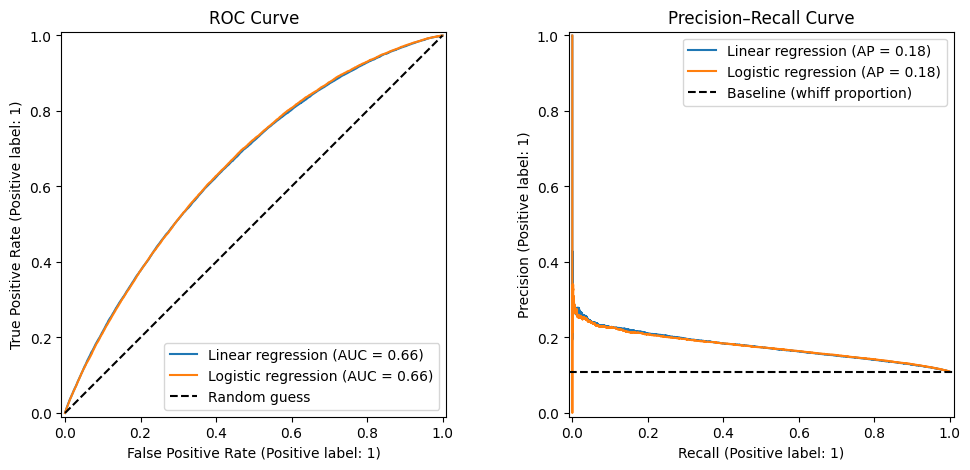

In [18]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, (predictions, scores) in model_predictions.items():
    RocCurveDisplay.from_predictions(y_test, scores, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, scores, name=name, ax=axes[1])

axes[0].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[0].set_title("ROC Curve")
axes[0].legend()
axes[1].axhline(y_test.mean(), color="k", linestyle="--", label="Baseline (whiff proportion)")
axes[1].set_title("Precision–Recall Curve")
axes[1].legend()
plt.show()

Both models have nearly identical curves (ROC AUC about 0.66; average precision about 0.18 versus a baseline of about 0.11). The models rank whiffs better than chance, but only modestly, so the large accuracy gap earlier comes from the classification threshold, not from better ranking.

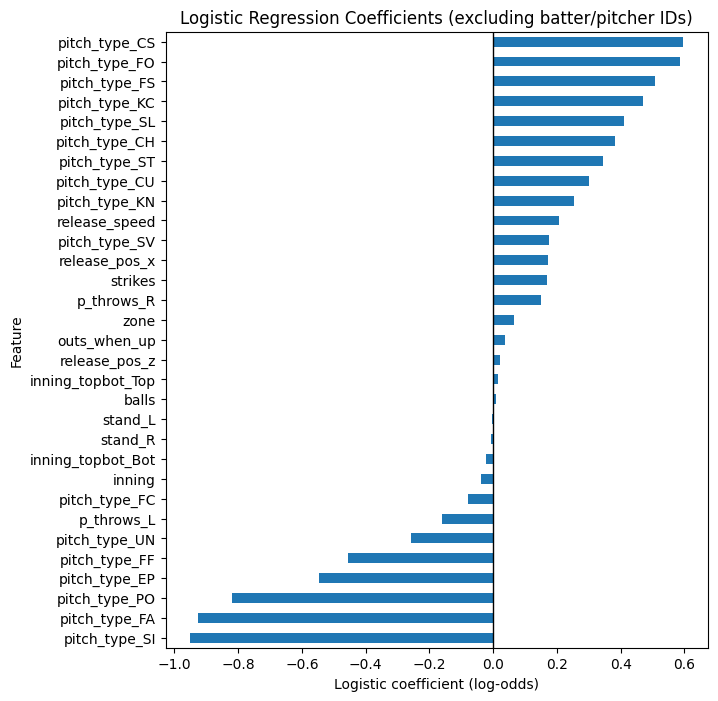

In [19]:
coefficients = pd.DataFrame({
    "Feature": logistic_feature_names,
    "Coefficient": logistic_model.named_steps["classification"].coef_[0],
})
coefficients = coefficients[~coefficients["Feature"].str.contains("batter_|pitcher_")]
coefficients["Feature"] = (coefficients["Feature"]
                           .str.replace("numeric__", "")
                           .str.replace("categorical__", ""))

ax = coefficients.sort_values("Coefficient").plot(
    kind="barh", x="Feature", y="Coefficient", figsize=(7, 8), legend=False)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Logistic coefficient (log-odds)")
ax.set_title("Logistic Regression Coefficients (excluding batter/pitcher IDs)")
plt.show()

The earlier coefficient table was dominated by individual batter and pitcher IDs, which can overfit to players with few pitches. Excluding IDs, the logistic coefficients agree with the EDA: breaking and offspeed pitch types (FS, KC, SL, CH, ST, CU) increase whiff odds, while sinkers (SI) and four-seam fastballs (FF) decrease them. Release speed and strikes also have positive coefficients, consistent with the speed and count plots.

Several of the largest coefficients belong to rare pitch types (CS, FO, PO, EP, FA, UN). These are based on few pitches and should not be over-interpreted. `zone` and `balls` have coefficients near zero even though location and count clearly matter in the EDA. This is likely because they enter the model as single linear terms: `zone` is a label (1–9, 11–14), not a quantity, and the effect of balls is driven mostly by 3–0 counts. Treating `zone` and the count as categories, and adding `plate_x` and `plate_z`, are natural next steps.

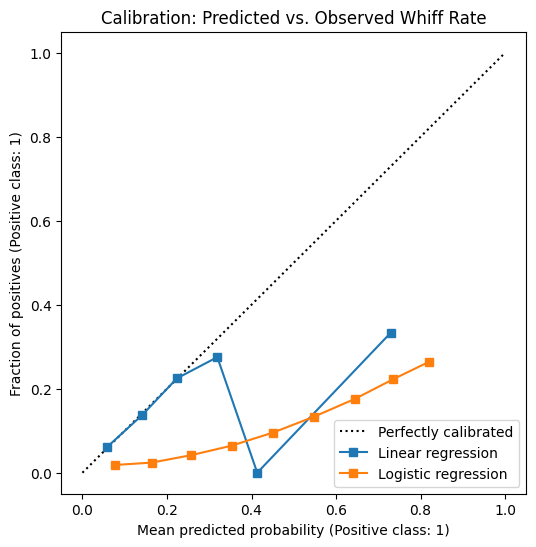

In [20]:
from sklearn.calibration import CalibrationDisplay

fig, ax = plt.subplots(figsize=(6, 6))
for name, (predictions, scores) in model_predictions.items():
    CalibrationDisplay.from_predictions(y_test, np.clip(scores, 0, 1),
                                        n_bins=10, name=name, ax=ax)
ax.set_title("Calibration: Predicted vs. Observed Whiff Rate")
plt.show()

A well-calibrated model follows the diagonal. Logistic regression falls well below it: for example, pitches given a predicted probability of about 0.8 are whiffs only about 26% of the time. This is expected because `class_weight="balanced"` up-weights whiffs during training, which pushes predicted probabilities upward. Its curve still rises steadily, so it ranks pitches correctly (consistent with its ROC AUC) even though its probabilities should not be read literally.

Linear regression is close to the diagonal for low predictions but erratic above about 0.3, where it makes very few predictions. It almost never predicts above 0.5, which explains why it classifies nearly every pitch as a non-whiff (recall about 0.00) despite its high accuracy. For a model that outputs meaningful whiff probabilities, the next step is logistic regression without class weighting (or with recalibration), combined with a threshold chosen for the goal rather than 0.5.

## Next Steps

- **Data:** Agree as a team on the final dataset (all pitches vs. swings only) and a shared cleaned CSV.
- **Features:** Treat `zone` and the ball–strike count as categorical; add plate location (`plate_x`, `plate_z`) and pitch movement/spin (`pfx_x`, `pfx_z`, `release_spin_rate`).
- **Models:** Refit logistic regression without class weighting or with recalibration, choose a decision threshold suited to our goal, and compare against random forest.
- **Evaluation:** Report ROC AUC, average precision, and log loss, with bootstrap confidence intervals.